# 02 — Scaled v3 experiment analysis

Europarl scaled v3: 12,000 train / 1,500 validation / 1,500 test sentence pairs. This notebook reads saved predictions and metrics without generating new translations. GPT-6 Astra is the C/D post-editor. The sampling comparison below uses GPT-6 reranking. Set `EXPERIMENT_SPLIT` to `validation` or `test` before execution. The older v2 experiment remains available through its saved results and Git history; no v2 outputs are loaded here.


In [1]:
from pathlib import Path
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATASET = "europarl_scaled_v3"
START = Path.cwd().resolve()
PROJECT_ROOT = next(
    (directory for directory in (START, *START.parents)
     if (directory / "data" / "processed" / DATASET).is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(f"Dataset {DATASET} not found above {START}")
SPLIT = os.environ.get("EXPERIMENT_SPLIT", "validation")  # Set to test for the already-frozen final evaluation.
assert SPLIT in {"validation", "test"}
DATA_DIR = PROJECT_ROOT / "data" / "processed" / DATASET
assert DATA_DIR.is_dir(), f"Missing dataset: {DATA_DIR}"
POSTEDIT_MODEL = os.environ.get("POSTEDIT_MODEL", "gpt6").lower()
assert POSTEDIT_MODEL == "gpt6"
LLM_SUFFIX = "_llm_gpt6"
COMET_SUFFIX = "_gpt6"
ARMS = {
    "A": "sentence_lora_balanced_scaled_v3",
    "B": "context_lora_balanced_scaled_v3",
    "C": f"sentence_lora_balanced_scaled_v3{LLM_SUFFIX}",
    "D": f"context_lora_balanced_scaled_v3{LLM_SUFFIX}",
}
KEYS = ["pair", "doc_id", "src_sent_id", "tgt_sent_id"]
print(f"Project: {PROJECT_ROOT} | Dataset: {DATASET} | Split: {SPLIT} | LLM: {POSTEDIT_MODEL}")


Project: D:\CIS600\context-mt | Dataset: europarl_scaled_v3 | Split: validation | LLM: gpt6


## Dataset provenance

Verify the exact CSV and builder manifest for this split. Predictions in A/B/C/D must align on the same sentence keys and source/reference text.


In [2]:
manifest = json.loads((DATA_DIR / "summary.json").read_text(encoding="utf-8"))
data_path = DATA_DIR / f"{SPLIT}.csv"
import hashlib
actual_hash = hashlib.sha256(data_path.read_bytes()).hexdigest()
assert manifest["csv_sha256"][SPLIT] == actual_hash, "Dataset differs from summary.json"
truth = pd.read_csv(data_path)
assert truth["split"].eq(SPLIT).all()
assert not truth.duplicated(KEYS).any(), "Duplicate example keys in dataset"
display(truth.groupby("pair").agg(examples=("src", "size"), documents=("doc_id", "nunique")))
print(f"SHA256 {SPLIT}: {actual_hash}")


,examples,documents
pair,,
en-de,1000,100
en-fr,500,100


SHA256 validation: 680700e2dd35b5d25c822af5df146a163eff18a637000960802757fb8bbabff9


## Four-arm comparison

A/B prediction tables come from mBART evaluation; C/D come from the selected LLM post-editor. GPT-6 is the C/D post-editor. Scores use the saved SacreBLEU and chrF metrics with one consistent reference per example. The code verifies both dataset hash provenance and row alignment before displaying a model.


In [3]:
reports, predictions, missing = {}, {}, []
for arm, run in ARMS.items():
    pred_path = PROJECT_ROOT / "outputs" / "predictions" / f"{run}_{SPLIT}.csv"
    metric_path = PROJECT_ROOT / "outputs" / "metrics" / f"{run}_{SPLIT}_metrics.json"
    if not pred_path.is_file() or not metric_path.is_file():
        missing.append(f"{arm}: {pred_path.name} / {metric_path.name}")
        continue
    report = json.loads(metric_path.read_text(encoding="utf-8"))
    if arm in "AB":
        assert report.get("dataset_sha256") == actual_hash, f"{arm}: metric dataset hash mismatch"
        assert report.get("split") == SPLIT, f"{arm}: wrong split"
    else:
        assert report.get("split") == SPLIT and not report.get("smoke_test"), f"{arm}: wrong split or smoke result"
        if POSTEDIT_MODEL == "gpt6":
            assert report.get("config", {}).get("provider") == "openai", f"{arm}: expected OpenAI post-edit"
    table = pd.read_csv(pred_path)
    assert len(table) == len(truth), f"{arm}: example count mismatch"
    assert not table.duplicated(KEYS).any(), f"{arm}: duplicate keys"
    aligned = truth[KEYS + ["src", "tgt", "previous_src"]].merge(
        table[KEYS + ["src", "tgt", "previous_src", "prediction"]],
        on=KEYS, how="left", validate="one_to_one", suffixes=("_gold", "_out"),
    )
    assert aligned["prediction"].notna().all(), f"{arm}: missing predictions"
    for field in ("src", "tgt", "previous_src"):
        assert aligned[f"{field}_gold"].equals(aligned[f"{field}_out"]), f"{arm}: {field} mismatch"
    reports[arm], predictions[arm] = report, aligned["prediction"].reset_index(drop=True)
print("Available arms:", ", ".join(reports) or "none yet")
if missing:
    print("Pending outputs:")
    for entry in missing:
        print(" -", entry)


Available arms: A, B, C, D


,arm,pair,N,BLEU,chrF
0,A,en-de,1000,29.168,58.941
1,A,en-fr,500,38.821,64.574
2,A,macro,1500,33.994,61.758
3,B,en-de,1000,29.114,58.833
4,B,en-fr,500,38.781,64.386
5,B,macro,1500,33.948,61.609
6,C,en-de,1000,32.895,62.072
7,C,en-fr,500,41.046,66.406
8,C,macro,1500,36.970,64.239
9,D,en-de,1000,32.766,62.131


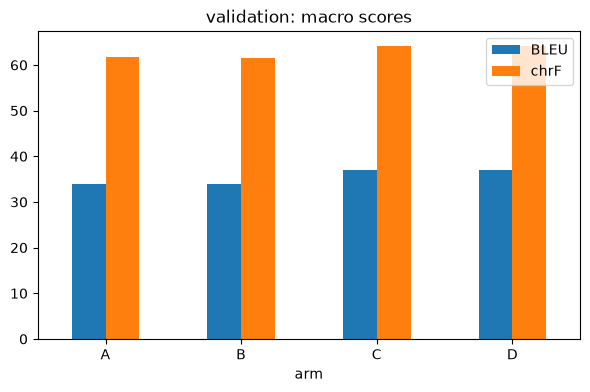

In [4]:
rows = []
for arm, report in reports.items():
    for pair in ("en-de", "en-fr"):
        pair_report = report["pairs"][pair]
        score = pair_report if arm in "AB" else pair_report["postedited"]
        rows.append({"arm": arm, "pair": pair, "N": pair_report["num_examples"],
                     "BLEU": score["sacrebleu"], "chrF": score["chrf"]})
    pair_rows = rows[-2:]
    rows.append({"arm": arm, "pair": "macro", "N": sum(r["N"] for r in pair_rows),
                 "BLEU": sum(r["BLEU"] for r in pair_rows) / 2,
                 "chrF": sum(r["chrF"] for r in pair_rows) / 2})
score_table = pd.DataFrame(rows, columns=["arm", "pair", "N", "BLEU", "chrF"])
if score_table.empty:
    print("Predictions and metrics for the chosen split are pending.")
else:
    display(score_table.round(3))
    macro = score_table[score_table["pair"] == "macro"].set_index("arm")
    display(macro[["BLEU", "chrF"]].plot.bar(rot=0, figsize=(7, 4), title=f"{SPLIT}: macro scores").figure)
    plt.close("all")


## Paired changes and qualitative examples

Compare translations for the **same** rows. Sentence-level chrF identifies candidates for manual inspection; it does not prove that a model resolved a pronoun or improved discourse. Review the source, preceding source and both translations before writing such claims in the report.


In [5]:
from sacrebleu.metrics import CHRF
chrf_metric = CHRF()
reference = truth["tgt"].tolist()
comparisons = {"context B − A": ("A", "B"), "LLM C − A": ("A", "C"),
               "LLM D − B": ("B", "D"), "context D − C": ("C", "D")}
summary = []
example_tables = {}
for name, (before, after) in comparisons.items():
    if before not in predictions or after not in predictions:
        continue
    old, new = predictions[before].tolist(), predictions[after].tolist()
    delta = [chrf_metric.sentence_score(b, [ref]).score -
             chrf_metric.sentence_score(a, [ref]).score
             for a, b, ref in zip(old, new, reference)]
    review = truth[KEYS + ["previous_src", "src", "tgt"]].copy()
    review[f"prediction_{before}"] = old
    review[f"prediction_{after}"] = new
    review["delta_sentence_chrF"] = delta
    example_tables[name] = review
    summary.append({"comparison": name, "changed": sum(a != b for a, b in zip(old, new)),
                    "helped": sum(d > 1e-9 for d in delta), "hurt": sum(d < -1e-9 for d in delta),
                    "tied": sum(abs(d) <= 1e-9 for d in delta),
                    "mean_sentence_chrF_delta": sum(delta) / len(delta)})
if summary:
    display(pd.DataFrame(summary).round(3))
    for name, table in example_tables.items():
        print(f"{name} — five largest positive changes")
        display(table.nlargest(5, "delta_sentence_chrF"))
        print(f"{name} — five largest negative changes")
        display(table.nsmallest(5, "delta_sentence_chrF"))
else:
    print("At least two complete arms are needed for paired examples.")


,comparison,changed,helped,hurt,tied,mean_sentence_chrF_delta
0,context B − A,746,365,374,761,0.022
1,LLM C − A,977,698,267,535,2.844
2,LLM D − B,1001,719,270,511,3.037
3,context D − C,830,429,396,675,0.214


context B − A — five largest positive changes


,pair,doc_id,src_sent_id,tgt_sent_id,previous_src,src,tgt,prediction_A,prediction_B,delta_sentence_chrF
295,en-de,en/ep-96-12-13.xml,1206,1265,Partly thanks to an unclear division of powers...,I will not go into the details.,Ich nenne keine Einzelheiten.,Ich werde nicht in die Details eingehen.,Ich werde nicht in die Einzelheiten eingehen.,32.805174
1346,en-de,en/ep-02-10-23.xml,1108,1149,(NL) There was a time when the preparation and...,This objective of secrecy has even survived th...,Dieser Wunsch nach Geheimhaltung hat sogar die...,Dieses Ziel des Geheimnisses hat sogar bei der...,Dieses Ziel der Geheimhaltung hat sogar die Ei...,31.085752
95,en-fr,en/ep-07-05-09-011.xml,81,87,I will stop now.,"Please accept my apologies, Mr President.","Veuillez accepter mes excuses, Monsieur le Pré...","Permettez -moi d'excuser, Monsieur le Président.","Prière d'accepter mes excuses, Monsieur le Pré...",26.721343
547,en-de,en/ep-11-05-10-006.xml,36,36,The agreement clearly states that the Council ...,It is unfortunate that the Council has not adh...,"Es ist bedauerlich, dass der Rat diese Vereinb...",Leider hat sich der Rat diesen Regelungen nich...,"Es ist bedauerlich, dass der Rat diesen Vorgab...",26.170459
149,en-de,en/ep-11-03-08-008.xml,169,182,What I cannot accept is that we need quotas to...,How patronising is that?,Denn wie gönnerhaft ist das?,Was für eine Schirmherrschaft?,Was für eine Schirmherrschaft ist das?,24.714217


context B − A — five largest negative changes


,pair,doc_id,src_sent_id,tgt_sent_id,previous_src,src,tgt,prediction_A,prediction_B,delta_sentence_chrF
405,en-fr,en/ep-04-10-13.xml,1747,1748,What indeed can be more splendid than equality...,"But where is this area, I ask myself?","Mais où est cet espace, je me le demande ?",Mais où est -ce que je me demande ?,Mais où se situe -t-il ?,-33.554546
615,en-fr,en/ep-96-12-13.xml,272,271,"In the same spirit, we have proposed that no d...",The reason for this is the obligation to make ...,Ce report s'explique par l'obligation de tenir...,La raison en est l'obligation de tenir compte ...,La raison en est l'obligation de tenir compte ...,-31.240963
890,en-de,en/ep-11-05-10-006.xml,255,259,"In the Committee on the Environment, Public He...",The error rate has reduced noticeably.,Die Fehler sind deutlich gesunken.,Die Fehlerquote ist deutlich gesunken.,Die Fehlerquote hat sich deutlich verringert.,-28.904299
1155,en-de,en/ep-04-01-12.xml,419,467,"Nothing came of it because some States, Spain ...","Since then, an Aviation Safety Agency has been...",Seitdem wurde eine Agentur für Luftverkehrssic...,Seitdem ist eine Agentur für Luftverkehrssiche...,Seitdem ist eine Agentur für Luftverkehrssiche...,-22.573264
221,en-de,en/ep-96-12-13.xml,272,286,"In the same spirit, we have proposed that no d...",The reason for this is the obligation to make ...,Erforderlich wird diese Verschiebung zum einen...,"Der Grund dafür ist die Verpflichtung, sowohl ...","Der Grund dafür ist die Verpflichtung, sowohl ...",-21.762035


LLM C − A — five largest positive changes


... (7 outputs left out)

context D − C — five largest positive changes


,pair,doc_id,src_sent_id,tgt_sent_id,previous_src,src,tgt,prediction_C,prediction_D,delta_sentence_chrF
201,en-de,en/ep-08-01-30-013.xml,32,34,Put the Treaty of Lisbon to the people.,Pactio Olisipiensis censenda est!,Pactio Olisipiensis censenda est!,Der Vertrag von Lissabon muss bewertet werden!,Pactio Olisipiensis censenda est!,89.028884
100,en-de,en/ep-09-03-10-013.xml,54,58,My group agrees with the other groups that exh...,"Congestion, though?",Aber Stau?,Aber Überlastung?,Aber Staus?,58.227596
547,en-de,en/ep-11-05-10-006.xml,36,36,The agreement clearly states that the Council ...,It is unfortunate that the Council has not adh...,"Es ist bedauerlich, dass der Rat diese Vereinb...",Leider hat sich der Rat nicht an diese Regelun...,"Es ist bedauerlich, dass der Rat sich nicht an...",48.911989
295,en-de,en/ep-96-12-13.xml,1206,1265,Partly thanks to an unclear division of powers...,I will not go into the details.,Ich nenne keine Einzelheiten.,Ich werde nicht auf die Details eingehen.,Ich werde nicht auf die Einzelheiten eingehen.,33.200627
1282,en-fr,en/ep-06-10-24-004.xml,41,41,Their life stands before us like a relief show...,We bow down before them.,Nous nous inclinons devant eux.,Nous nous prosternons devant eux.,Nous nous inclinons devant eux.,32.351368


context D − C — five largest negative changes


,pair,doc_id,src_sent_id,tgt_sent_id,previous_src,src,tgt,prediction_C,prediction_D,delta_sentence_chrF
614,en-de,en/ep-07-07-10-018.xml,5,6,"Generally speaking, the first railway package ...",The opening of the networks in Europe to rail ...,Die Öffnung der Netze in Europa für den Eisenb...,Die Öffnung der Netze in Europa für den Eisenb...,Die Öffnung der Eisenbahnnetze in Europa für d...,-30.859004
634,en-de,en/ep-06-11-13-015.xml,147,176,Mr Bush's and Mr Blair's invasion and occupati...,We can no longer look on passively.,Wir können nicht länger tatenlos zusehen.,Wir können nicht länger tatenlos zusehen.,Wir können nicht länger passiv zusehen.,-29.926208
280,en-de,en/ep-09-02-04-012.xml,209,218,The European Globalisation Adjustment Fund sho...,Labour must then be restored to its central pl...,Die Arbeit muss dann wieder ihren zentralen Pl...,Dann muss die Arbeit wieder ihren zentralen Pl...,Der Arbeit muss dann in Europa wieder ihr zent...,-29.517529
101,en-de,en/ep-03-04-08.xml,1619,1676,"Is this the outward-, forward-looking one?",There are so many different concepts floating ...,Es sind so viele verschiedene Begriffe im Umlauf.,Es sind so viele verschiedene Konzepte im Umlauf.,Es kursieren so viele verschiedene Konzepte.,-28.957511
890,en-de,en/ep-11-05-10-006.xml,255,259,"In the Committee on the Environment, Public He...",The error rate has reduced noticeably.,Die Fehler sind deutlich gesunken.,Die Fehlerquote ist deutlich gesunken.,Die Fehlerquote hat sich deutlich verringert.,-28.904299


## COMET

Read saved reference-based COMET results for A/B/C/D on the selected split and selected post-editor. Small descriptive mean differences do not by themselves establish statistical significance or a causal context effect.


In [6]:
comet_path = PROJECT_ROOT / "outputs" / "metrics" / f"comet_{SPLIT}_scaled_v3{COMET_SUFFIX}_metrics.json"
if comet_path.is_file():
    comet_report = json.loads(comet_path.read_text(encoding="utf-8"))
    assert comet_report.get("dataset") == "scaled_v3"
    assert comet_report.get("split") == SPLIT
    if POSTEDIT_MODEL == "gpt6":
        assert comet_report.get("postedit_model") == "gpt6"
    assert comet_report["inputs"]["dataset"]["sha256"] == actual_hash
    comet_rows = []
    for arm, details in comet_report["arms"].items():
        for pair, metrics in details["pairs"].items():
            comet_rows.append({"arm": arm, "pair": pair, "COMET": metrics["comet_mean"]})
        comet_rows.append({"arm": arm, "pair": "macro",
                           "COMET": details["macro_average_comet"]})
    display(pd.DataFrame(comet_rows).round(4))
    display(pd.DataFrame([{"comparison": name, "COMET delta": value["macro_comet_delta"]}
                          for name, value in comet_report["comparisons"].items()]).round(4))
else:
    print(f"COMET pending: {comet_path.name}")


,arm,pair,COMET
0,A,en-de,0.8685
1,A,en-fr,0.8712
2,A,macro,0.8699
3,B,en-de,0.8698
4,B,en-fr,0.8702
5,B,macro,0.8700
6,C,en-de,0.8885
7,C,en-fr,0.8877
8,C,macro,0.8881
9,D,en-de,0.8902


,comparison,COMET delta
0,context_without_llm,0.0001
1,llm_sentence,0.0182
2,llm_context,0.0196
3,context_with_llm,0.0015


## Paired document bootstrap

Intervals resample shared document IDs across both language pairs. C−A and D−B measure GPT-6 post-editing against its matching mBART draft. D−C isolates the small context difference after post-editing. Interpret these conditional intervals alongside BLEU, chrF and human review; the notebook reads saved JSON and does not call an LLM.


In [7]:
bootstrap_path = PROJECT_ROOT / "outputs" / "metrics" / f"document_bootstrap_{SPLIT}_scaled_v3{COMET_SUFFIX}.json"
if bootstrap_path.is_file():
    bootstrap = json.loads(bootstrap_path.read_text(encoding="utf-8"))
    assert bootstrap.get("split") == SPLIT
    assert bootstrap.get("postedit_model") == POSTEDIT_MODEL
    assert bootstrap.get("examples") == len(truth)
    intervals = []
    for metric, contrasts in bootstrap["results"].items():
        for name, result in contrasts.items():
            lo, hi = result["ci95_percentile"]
            intervals.append({"metric": metric, "contrast": name,
                              "delta": result["observed_delta"], "CI low": lo, "CI high": hi})
    display(pd.DataFrame(intervals).round(4))
else:
    print("Document bootstrap pending:", bootstrap_path)


,metric,contrast,delta,CI low,CI high
0,bleu,context_B_minus_A,-0.0468,-0.3513,0.3207
1,bleu,llm_on_sentence_C_minus_A,2.9759,2.4239,3.4186
2,bleu,llm_on_context_D_minus_B,2.9718,2.4631,3.4033
3,bleu,context_with_llm_D_minus_C,-0.0509,-0.4211,0.3400
4,chrf,context_B_minus_A,-0.1483,-0.4380,0.1153
5,chrf,llm_on_sentence_C_minus_A,2.4813,2.1864,2.7838
6,chrf,llm_on_context_D_minus_B,2.6036,2.2610,2.9536
7,chrf,context_with_llm_D_minus_C,-0.0260,-0.2224,0.1714
8,comet,context_B_minus_A,0.0001,-0.0013,0.0015
9,comet,llm_on_sentence_C_minus_A,0.0182,0.0152,0.0212


## Decoding ablation: Top-k and Top-p

Sampling was evaluated on **validation only**. The beam setting was frozen before the v3 test run. A positive COMET change with falling BLEU/chrF is reported as mixed evidence. The GPT-6 reranker does not see the gold reference.


In [8]:
if SPLIT == 'validation':
    decoding_root = PROJECT_ROOT / 'outputs' / 'decoding' / 'scaled_v3'
    folders = {
        'Top-k': decoding_root / 'validation_top_k_k50_n3_t0p8_seed42_gpt6',
        'Top-p': decoding_root / 'validation_top_p_p0p9_n3_t0p8_seed42_gpt6',
    }
    decoding_rows = []
    for name, folder in folders.items():
        path = folder / 'metrics.json'
        if not path.is_file():
            print(f'Pending {name}: {path}')
            continue
        result = json.loads(path.read_text(encoding='utf-8'))
        assert result['config']['dataset_sha256'] == actual_hash
        assert result['config']['split'] == 'validation' and not result['smoke_test']
        for pair, values in result['pairs'].items():
            decoding_rows.append({'method': name, 'pair': pair, 'N': values['num_examples'],
                                  'changed': values['changed'],
                                  'beam BLEU': values['beam_bleu'],
                                  'selected BLEU': values['reranked_bleu'],
                                  'beam chrF': values['beam_chrf'],
                                  'selected chrF': values['reranked_chrf']})
    if decoding_rows:
        display(pd.DataFrame(decoding_rows).round(3))
    comet_sampling_path = decoding_root / 'validation_comet_comparison_gpt6' / 'metrics.json'
    if comet_sampling_path.is_file():
        sampling_comet = json.loads(comet_sampling_path.read_text(encoding='utf-8'))
        assert sampling_comet['provenance']['dataset'] == actual_hash
        comet_rows = []
        for method, value in sampling_comet['summary'].items():
            for pair, item in value['pairs'].items():
                comet_rows.append({'method': method, 'pair': pair, 'COMET': item['comet_mean'],
                                   'delta vs beam': item['mean_delta_vs_beam']})
            comet_rows.append({'method': method, 'pair': 'macro', 'COMET': value['macro_comet'],
                               'delta vs beam': value['macro_delta_vs_beam']})
        display(pd.DataFrame(comet_rows).round(4))
    else:
        print('Sampling COMET pending: run scripts/09_evaluate_decoding_comet.py')
else:
    print('Sampling ablation was selected on validation; the test split is not loaded here.')


,method,pair,N,changed,beam BLEU,selected BLEU,beam chrF,selected chrF
0,Top-k,en-de,1000,232,29.114,28.743,58.833,58.705
1,Top-k,en-fr,500,130,38.781,38.688,64.386,64.443
2,Top-p,en-de,1000,321,29.114,28.680,58.833,58.768
3,Top-p,en-fr,500,187,38.781,38.604,64.386,64.309


,method,pair,COMET,delta vs beam
0,beam,en-de,0.8698,0.0000
1,beam,en-fr,0.8702,0.0000
2,beam,macro,0.8700,0.0000
3,top_k,en-de,0.8721,0.0023
4,top_k,en-fr,0.8731,0.0029
5,top_k,macro,0.8726,0.0026
6,top_p,en-de,0.8721,0.0024
7,top_p,en-fr,0.8732,0.0030
8,top_p,macro,0.8727,0.0027


## Interpretation

Read the per-pair rows before interpreting equal-pair macro averages. Differences between validation and test or between Europarl v2 and v3 are not controlled model comparisons across datasets. Blinded AI judgments are exploratory error analysis, not human evaluation. A preceding sentence may clarify a referent, but a score change alone does not prove that context caused the translation improvement.


## Balanced versus unweighted LoRA

These four models share the v3 dataset and evaluation split. The unweighted models are an ablation, kept separate from the A/B/C/D post-edit experiment. Check dataset hashes before comparing scores.


In [9]:
ABLATED = {
    "sentence_balanced": "sentence_lora_balanced_scaled_v3",
    "sentence_unweighted": "sentence_lora_unweighted_scaled_v3",
    "context_balanced": "context_lora_balanced_scaled_v3",
    "context_unweighted": "context_lora_unweighted_scaled_v3",
}
ablation_rows = []
for label, run in ABLATED.items():
    path = PROJECT_ROOT / "outputs" / "metrics" / f"{run}_{SPLIT}_metrics.json"
    if not path.is_file():
        print("Pending ablation metrics:", path.name)
        continue
    result = json.loads(path.read_text(encoding="utf-8"))
    assert result["split"] == SPLIT and result["dataset_sha256"] == actual_hash
    for pair in ("en-de", "en-fr"):
        score = result["pairs"][pair]
        ablation_rows.append({"model": label, "pair": pair,
                              "BLEU": score["sacrebleu"], "chrF": score["chrf"]})
    ablation_rows.append({"model": label, "pair": "macro",
                          "BLEU": result["macro_average_sacrebleu"],
                          "chrF": result["macro_average_chrf"]})
if ablation_rows:
    display(pd.DataFrame(ablation_rows).round(3))


,model,pair,BLEU,chrF
0,sentence_balanced,en-de,29.168,58.941
1,sentence_balanced,en-fr,38.821,64.574
2,sentence_balanced,macro,33.994,61.758
3,sentence_unweighted,en-de,29.417,59.090
4,sentence_unweighted,en-fr,38.529,64.531
5,sentence_unweighted,macro,33.973,61.811
6,context_balanced,en-de,29.114,58.833
7,context_balanced,en-fr,38.781,64.386
8,context_balanced,macro,33.948,61.609
9,context_unweighted,en-de,29.132,58.926


## Blinded error review

A/B/C/D and beam/Top-k/Top-p comparisons require separate blind review sheets made from the GPT-6 validation score tables. The labels for pronouns, references, terminology and meaning must be completed by bilingual reviewers; metric scores alone do not supply those judgments. See `docs/human_review_protocol.md` and `scripts/11_build_manual_review.py`.


In [10]:
if SPLIT == 'validation':
    for label, relative in {
        'A/B/C/D': 'outputs/analysis/abcd_validation_scaled_v3_gpt6/manual_review/blind_review.csv',
        'beam/Top-k/Top-p': 'outputs/analysis/decoding_validation_scaled_v3_gpt6/manual_review/blind_review.csv',
    }.items():
        path = PROJECT_ROOT / relative
        print(f'{label} blind review: {path if path.is_file() else "pending bilingual annotation"}')
else:
    print('Manual review is planned on validation only.')


A/B/C/D blind review: D:\CIS600\context-mt\outputs\analysis\abcd_validation_scaled_v3_gpt6\manual_review\blind_review.csv
beam/Top-k/Top-p blind review: pending bilingual annotation
